### Trying out a linear model:

In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
import seaborn as sns

%config InlineBackend.figure_format = 'png'
import matplotlib.pyplot as plt
%matplotlib inline

/opt/conda/lib/python3.5/site-packages/sklearn/cross_validation.py:43: DeprecationWarning: This module was deprecated in version 0.18 in favor of the model_selection module into which all the refactored classes and functions are moved. Also note that the interface of the new CV iterators are different from that of this module. This module will be removed in 0.20.
  "This module will be removed in 0.20.", DeprecationWarning)


In [2]:
train = pd.read_csv("../input/train.csv")
test = pd.read_csv("../input/test.csv")

In [3]:
train["SalePrice"] = np.log(train["SalePrice"]) + 1

In [4]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,13.247694
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,13.109011
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,13.317167
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,12.849398
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,13.429216


In [5]:
all_data = pd.concat((train.loc[:,'MSSubClass':'SaleCondition'],
                      test.loc[:,'MSSubClass':'SaleCondition']))

In [6]:
#log1p transform numeric features:
types = all_data.dtypes
all_data.loc[:,types[types != "object"].index] = np.log1p(all_data.loc[:,types[types != "object"].index])

In [7]:
all_data = pd.get_dummies(all_data)

In [8]:
all_data.shape

(2919, 288)

In [9]:
#eliminating low variance feats:
#feat_var = all_data.var()
#good_columns = feat_var[feat_var > 0.002].index

#all_data = all_data[good_columns]

In [10]:
#filling NA's with the mean of the column:
all_data = all_data.fillna(all_data.mean())

In [11]:
X_train = all_data[:train.shape[0]].values
X_test = all_data[train.shape[0]:].values
y = train.SalePrice

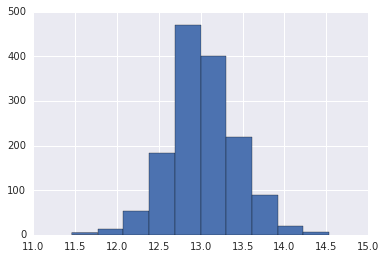

In [12]:
y.hist()

###Models

In [13]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import BaggingRegressor
from xgboost import XGBRegressor

In [14]:
#model = BaggingRegressor(Ridge())
model_ridge = Ridge()
model_xgb = XGBRegressor(n_estimators=360,max_depth=2)

In [15]:
def rmse_cv(model):
    rmse= np.sqrt(-cross_val_score(model, X_train, y, scoring="mean_squared_error", cv = 5))
    return(rmse)

In [16]:
rmse_cv(model_ridge).mean()

0.13325710361911627

In [17]:
rmse_cv(model_xgb).mean()

0.12477090274462695

In [18]:
alphas = [0.05, 0.1, 0.3, 1, 3, 10, 15, 30, 50, 75]
cv_ridge = [rmse_cv(Ridge(alpha = alpha)).mean() 
            for alpha in alphas]

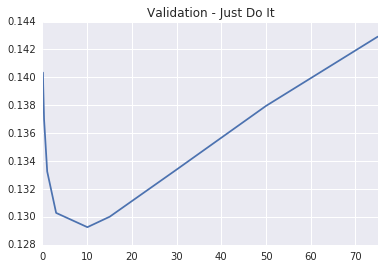

In [19]:
cv_ridge = pd.Series(cv_ridge, index = alphas)
cv_ridge.plot(title = "Validation - Just Do It")

In [20]:
best_alpha = cv_ridge.argmin()

In [21]:
model_ridge = Ridge(alpha = best_alpha).fit(X_train, y)

In [22]:
preds = np.expm1(model_ridge.predict(X_test))

In [23]:
solution = pd.DataFrame({"id":test.Id, "SalePrice":preds})
solution.to_csv("ridge_sol.csv")